# 03 – Report figures

Builds every figure in the report from `data/clean/`, in the shared style from `style.py`. Each figure is saved to
`figures/` as a PDF (for LaTeX) and a PNG (for previews). Run top to bottom; it takes about a minute.

| Figure | Question | Plot type | What it supports |
|---|---|---|---|
| 1 | Q1 | Line chart + moving average | Big swings with no clear trend from 1980, then three extreme years; 2023 is 2.3× the old record |
| 2 | Q1 | Heat map (year × month) | Area burns in May–August; May–July 2023 are the most extreme months on record |
| 3 | Q2 | 100% stacked bars | Lightning starts under half of fires but burns most of the area, in almost every province |
| 4 | Q2 | Radial (polar) chart | Human fires peak in spring, lightning fires in late July |
| 5 | Q3 | Histogram + cumulative share curve | Most fires are tiny; 0.2% of fires burn half the area |
| 6 | Q3 | Box plots by decade | The typical large fire has roughly doubled in size |
| 7 | Q4 | Choropleth | Hotspots per km²: Saskatchewan, Manitoba, NWT, Alberta |
| 8 | Q4 | Small-multiple maps | Where the area burned in each decade, and BC's recent rise |

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import BoundaryNorm, LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

import style

style.apply()

CLEAN = "../data/clean/"
fires = pd.read_parquet(CLEAN + "fires.parquet")
provinces = gpd.read_parquet(CLEAN + "provinces.parquet")
perimeters = gpd.read_parquet(CLEAN + "perimeters.parquet")

annual = fires.groupby("year")["size_ha"].sum() / 1e6   # Mha per year
percent = FuncFormatter(lambda v, _: f"{v:.0f}%")

## Figure 1 – Area burned per year (Q1)

Linear scale on purpose: the point is how far 2023 sits above everything else. The 10-year average is trailing (each
point averages that year and the nine before), so it never uses future years.

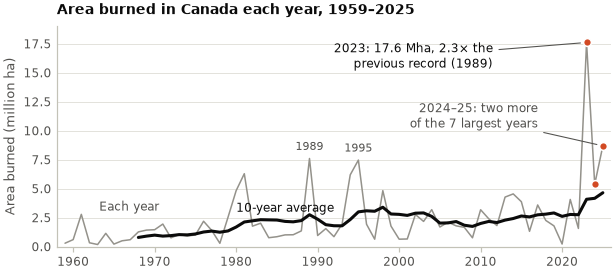

In [2]:
rolling = annual.rolling(10).mean()
highlight = [2023, 2024, 2025]

fig, ax = plt.subplots(figsize=(style.FULL_WIDTH, 2.6))
style.ygrid(ax)
ax.plot(annual.index, annual, color=style.NEUTRAL, lw=1)
ax.plot(rolling.index, rolling, color=style.INK, lw=2)
ax.scatter(highlight, annual[highlight], s=26, color=style.ACCENT, zorder=3, edgecolor="white", linewidth=1)

ax.annotate("2023: 17.6 Mha, 2.3× the\nprevious record (1989)", xy=(2023, annual[2023]), xytext=(2011.5, 16.4),
            ha="right", va="center", fontsize=8, color=style.INK,
            arrowprops=dict(arrowstyle="-", color=style.SECONDARY, lw=0.7, shrinkB=4))
ax.annotate("2024–25: two more\nof the 7 largest years", xy=(2025, annual[2025]), xytext=(2017, 11.2),
            ha="right", va="center", fontsize=8, color=style.SECONDARY,
            arrowprops=dict(arrowstyle="-", color=style.SECONDARY, lw=0.7, shrinkB=4))
ax.text(1989, annual[1989] + 0.5, "1989", ha="center", va="bottom", fontsize=7.5, color=style.SECONDARY)
ax.text(1995, annual[1995] + 0.5, "1995", ha="center", va="bottom", fontsize=7.5, color=style.SECONDARY)
ax.text(1986, 3.0, "10-year average", fontsize=8, color=style.INK, ha="center")
ax.text(1963.2, 3.1, "Each year", fontsize=8, color=style.SECONDARY)

ax.set_xlim(1958, 2026)
ax.set_ylim(0, 19)
ax.set_ylabel("Area burned (million ha)")
ax.set_title("Area burned in Canada each year, 1959–2025")
style.save(fig, "fig1_annual_area")

## Figure 2 – Area burned by year and month (Q1)

Colour is on a log scale, because a quiet month and a record month differ by a factor of over 10,000. Only April–October
are shown: the other five months together hold under 1% of the area burned. The month is the month the fire was reported.

Area outside Apr–Oct: 0.35%


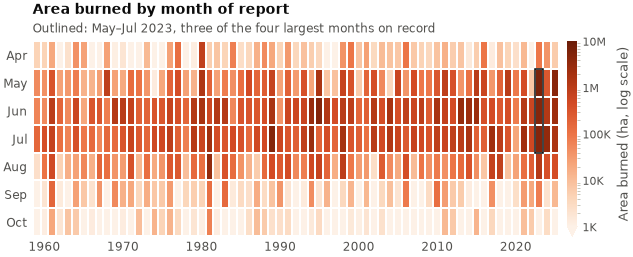

In [3]:
months = [4, 5, 6, 7, 8, 9, 10]
month_names = ["Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct"]
dated = fires.dropna(subset=["month"])
grid = dated.groupby(["month", "year"])["size_ha"].sum().unstack(fill_value=0).reindex(months)
outside = 1 - dated.loc[dated["month"].isin(months), "size_ha"].sum() / dated["size_ha"].sum()
print(f"Area outside Apr–Oct: {outside:.2%}")

fig, ax = plt.subplots(figsize=(style.FULL_WIDTH, 2.3))
norm = LogNorm(vmin=1e3, vmax=1e7, clip=True)
mesh = ax.pcolormesh(grid.columns, np.arange(len(months)), grid.where(grid > 0).to_numpy(), cmap=style.HEAT,
                     norm=norm, shading="nearest", edgecolor="white", linewidth=0.3)
mesh.cmap.set_bad(style.HEAT_STEPS[0])
mesh.cmap.set_under(style.HEAT_STEPS[0])
ax.add_patch(plt.Rectangle((2022.5, 0.5), 1, 3, fill=False, edgecolor=style.INK, lw=1))
ax.text(0.0, 1.03, "Outlined: May–Jul 2023, three of the four largest months on record", transform=ax.transAxes,
        ha="left", va="bottom", fontsize=8, color=style.SECONDARY)

ax.set_yticks(range(len(months)), month_names)
ax.invert_yaxis()
ax.set_xlim(1958.5, 2025.5)
ax.spines[["left", "bottom"]].set_visible(False)
ax.tick_params(axis="x", length=0)
ax.set_title("Area burned by month of report", pad=18)
bar = fig.colorbar(mesh, ax=ax, pad=0.015, fraction=0.035, extend="min")
bar.set_ticks([1e3, 1e4, 1e5, 1e6, 1e7], labels=["1K", "10K", "100K", "1M", "10M"])
bar.set_label("Area burned (ha, log scale)", color=style.SECONDARY)
bar.outline.set_visible(False)
bar.ax.tick_params(length=0, labelsize=7.5)
style.save(fig, "fig2_year_month_heatmap")

## Figure 3 – Share of fires vs share of area, by cause and province (Q2)

Provinces are ordered by total area burned. Prince Edward Island (74 ha in 67 years) is left out; Nunavut is kept because
almost all of its few fires are lightning fires.

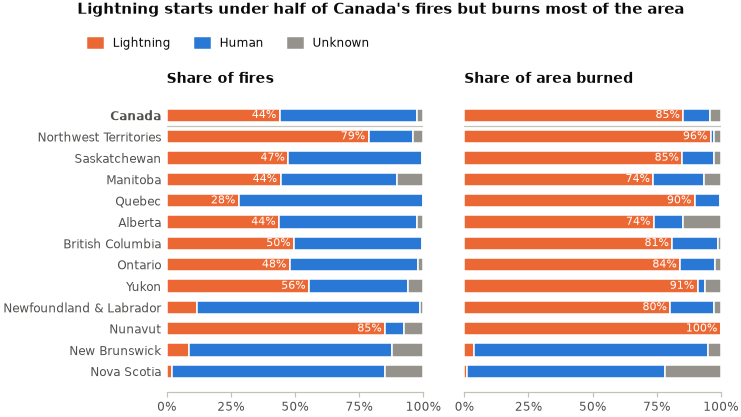

In [4]:
order = (fires.groupby("province")["size_ha"].sum().drop("PE").sort_values(ascending=False).index.tolist())
names = provinces.set_index("province")["name"].replace({"Newfoundland and Labrador": "Newfoundland & Labrador"})

counts = fires.groupby(["province", "cause"], observed=True).size().unstack(fill_value=0)
area = fires.groupby(["province", "cause"], observed=True)["size_ha"].sum().unstack(fill_value=0)
counts.loc["Canada"] = counts.sum()
area.loc["Canada"] = area.sum()
rows = ["Canada"] + order
share = {"Share of fires": counts.loc[rows], "Share of area burned": area.loc[rows]}

fig, axes = plt.subplots(1, 2, figsize=(style.FULL_WIDTH, 3.5), sharey=True, gridspec_kw={"wspace": 0.16})
y = np.arange(len(rows))
for ax, (title, table) in zip(axes, share.items()):
    pct = table[style.CAUSE_ORDER].div(table.sum(axis=1), axis=0) * 100
    left = np.zeros(len(rows))
    for cause in style.CAUSE_ORDER:
        ax.barh(y, pct[cause], left=left, height=0.62, color=style.CAUSE_COLORS[cause],
                edgecolor="white", linewidth=1)
        left += pct[cause].to_numpy()
    lightning = pct["Lightning"]
    for i, value in enumerate(lightning):
        if value >= 12:
            ax.text(value - 1.5, i, f"{value:.0f}%", ha="right", va="center", fontsize=7, color="white")
    ax.set_title(title)
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(percent)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.spines["left"].set_visible(False)

axes[0].set_yticks(y, ["Canada"] + [names[p] for p in order])
axes[0].get_yticklabels()[0].set_fontweight("bold")
axes[0].invert_yaxis()
axes[0].axhline(0.5, color=style.AXIS, lw=0.8)
axes[1].axhline(0.5, color=style.AXIS, lw=0.8)
handles = [Patch(color=style.CAUSE_COLORS[c], label=c) for c in style.CAUSE_ORDER]
fig.legend(handles=handles, ncol=3, loc="upper left", bbox_to_anchor=(0.0, 1.06))
fig.suptitle("Lightning starts under half of Canada's fires but burns most of the area",
             x=0.0, y=1.12, ha="left", fontsize=9.5, fontweight="bold")
style.save(fig, "fig3_cause_by_province")

## Figure 4 – The fire season by cause (Q2)

A radial chart suits the yearly cycle: December runs into January with no break. Each line is the share of that cause's
fires reported in each week, so the two causes can be compared even though their totals differ. Unknown-cause fires
(2.5%) are left out.

Human peak: week 18 (6.8% of that cause's fires)
Lightning peak: week 31 (10.9% of that cause's fires)


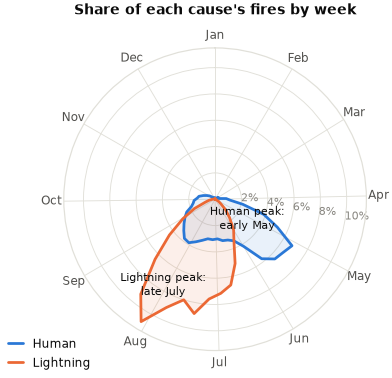

In [5]:
dated = fires.dropna(subset=["doy"])
dated = dated[dated["cause"] != "Unknown"]
week = ((dated["doy"] - 1) // 7).clip(upper=51)
weekly = dated.groupby([week, "cause"], observed=True).size().unstack(fill_value=0).reindex(range(52), fill_value=0)
weekly = weekly[["Human", "Lightning"]] / weekly[["Human", "Lightning"]].sum() * 100
theta = (np.arange(52) + 0.5) / 52 * 2 * np.pi

fig, ax = plt.subplots(figsize=(style.HALF_WIDTH + 0.4, style.HALF_WIDTH + 0.6), subplot_kw={"projection": "polar"})
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
for cause in ["Human", "Lightning"]:
    r = np.append(weekly[cause].to_numpy(), weekly[cause].iloc[0])
    t = np.append(theta, theta[0])
    ax.plot(t, r, color=style.CAUSE_COLORS[cause], lw=1.8, label=cause)
    ax.fill(t, r, color=style.CAUSE_COLORS[cause], alpha=0.1, lw=0)

month_starts = pd.to_datetime([f"2001-{m:02d}-01" for m in range(1, 13)]).dayofyear - 1
ax.set_xticks(month_starts / 365 * 2 * np.pi, ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug",
                                                 "Sep", "Oct", "Nov", "Dec"])
ax.tick_params(axis="x", colors=style.SECONDARY, pad=-2)
ax.set_rlim(0, np.ceil(weekly.to_numpy().max()) + 0.5)
ax.set_rticks([2, 4, 6, 8, 10], ["2%", "4%", "6%", "8%", "10%"])
ax.set_rlabel_position(100)
ax.tick_params(axis="y", labelsize=7, labelcolor=style.MUTED)
ax.grid(color=style.GRID, lw=0.6)
ax.spines["polar"].set_color(style.GRID)

PEAK_LABEL_R = {"Human": 0.42, "Lightning": 0.7}   # where along the peak spoke each label sits
for cause, label in [("Human", "Human peak:\nearly May"), ("Lightning", "Lightning peak:\nlate July")]:
    peak = weekly[cause].idxmax()
    print(f"{cause} peak: week {peak + 1} ({weekly[cause].max():.1f}% of that cause's fires)")
    ax.text(theta[peak], weekly[cause].max() * PEAK_LABEL_R[cause], label, ha="center", va="center",
            fontsize=7.5, color=style.INK)
ax.legend(loc="lower left", bbox_to_anchor=(-0.22, -0.1), ncol=1)
ax.set_title("Share of each cause's fires by week", pad=22, loc="center")
style.save(fig, "fig4_fire_season_radial")

## Figure 5 – Fire sizes and how concentrated the area is (Q3)

(a) uses the same log-size bins for two distributions: how many fires fall in each size range, and how much area they
burned. (b) sorts fires from largest to smallest and adds up their area. Fires recorded as 0 ha are excluded (log scale).

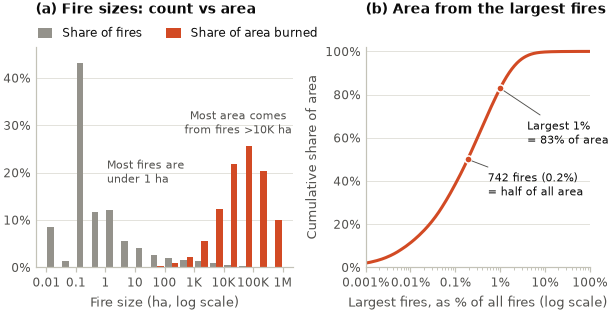

In [6]:
sized = fires.loc[fires["has_size"], "size_ha"]
bins = np.arange(-2, 6.5, 0.5)
fires_pct = np.histogram(np.log10(sized), bins=bins)[0] / len(sized) * 100
area_pct = np.histogram(np.log10(sized), bins=bins, weights=sized)[0] / sized.sum() * 100

desc = np.sort(sized.to_numpy())[::-1]
cum = desc.cumsum() / desc.sum() * 100
top_pct = np.arange(1, len(desc) + 1) / len(desc) * 100
half = np.searchsorted(cum, 50)
one_pct = int(0.01 * len(desc)) - 1

fig, (a, b) = plt.subplots(1, 2, figsize=(style.FULL_WIDTH, 2.6), gridspec_kw={"wspace": 0.3, "width_ratios": [1.15, 1]})
style.ygrid(a)
width = 0.22
centers = bins[:-1] + 0.25
a.bar(centers - width / 2, fires_pct, width=width, color=style.NEUTRAL, label="Share of fires")
a.bar(centers + width / 2, area_pct, width=width, color=style.ACCENT, label="Share of area burned")
a.set_xticks(range(-2, 7), ["0.01", "0.1", "1", "10", "100", "1K", "10K", "100K", "1M"])
a.set_xlabel("Fire size (ha, log scale)")
a.yaxis.set_major_formatter(percent)
a.set_ylim(0, fires_pct.max() * 1.08)
a.legend(loc="lower left", bbox_to_anchor=(-0.02, 1.0), ncol=2, borderaxespad=0.2)
a.text(0.05, 23, "Most fires are\nunder 1 ha", fontsize=7.5, color=style.SECONDARY, ha="left", va="top")
a.text(4.5, 28.3, "Most area comes\nfrom fires >10K ha", fontsize=7.5, color=style.SECONDARY, ha="center")
a.set_title("(a) Fire sizes: count vs area", pad=22)

style.ygrid(b)
b.plot(top_pct, cum, color=style.ACCENT, lw=2)
for i, label, offset in [(half, f"{half + 1:,} fires (0.2%)\n= half of all area", (2.8, -12)),
                         (one_pct, "Largest 1%\n= 83% of area", (4, -21))]:
    b.scatter(top_pct[i], cum[i], s=22, color=style.ACCENT, edgecolor="white", linewidth=1, zorder=3)
    b.annotate(label, xy=(top_pct[i], cum[i]), xytext=(top_pct[i] * offset[0], cum[i] + offset[1]),
               fontsize=7.5, color=style.INK, va="center",
               arrowprops=dict(arrowstyle="-", color=style.SECONDARY, lw=0.6, shrinkB=3))
b.set_xscale("log")
b.set_xlim(1e-3, 100)
b.set_ylim(0, 102)
b.set_xticks([1e-3, 1e-2, 0.1, 1, 10, 100], ["0.001%", "0.01%", "0.1%", "1%", "10%", "100%"])
b.yaxis.set_major_formatter(percent)
b.set_xlabel("Largest fires, as % of all fires (log scale)")
b.set_ylabel("Cumulative share of area")
b.set_title("(b) Area from the largest fires", pad=22)
style.save(fig, "fig5_size_concentration")

## Figure 6 – Size of large fires by decade (Q3)

Only fires ≥ 200 ha, because small fires were under-reported in early decades. 1959 (the only 1950s year) is left out;
the 2020s cover 2020–2025. Boxes show the middle 50% of fires, whiskers the 10th–90th percentiles, on a log scale.

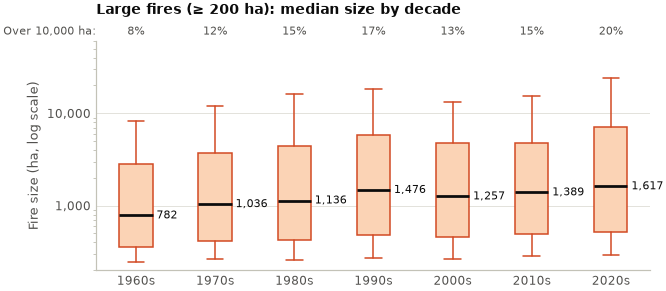

In [7]:
decades = ["1960s", "1970s", "1980s", "1990s", "2000s", "2010s", "2020s"]
large = fires[fires["is_large"] & fires["decade"].isin(decades)]
groups = [large.loc[large["decade"] == d, "size_ha"].to_numpy() for d in decades]
medians = [np.median(g) for g in groups]
over_10k = [(g >= 10_000).mean() * 100 for g in groups]

fig, ax = plt.subplots(figsize=(style.FULL_WIDTH, 2.7))
style.ygrid(ax)
ax.boxplot(groups, tick_labels=decades, whis=(10, 90), showfliers=False, widths=0.42, patch_artist=True,
           boxprops=dict(facecolor="#fbd3b5", edgecolor=style.ACCENT, lw=1),
           whiskerprops=dict(color=style.ACCENT, lw=1), capprops=dict(color=style.ACCENT, lw=1),
           medianprops=dict(color=style.INK, lw=1.8))
for i, m in enumerate(medians, start=1):
    ax.text(i + 0.26, m, f"{m:,.0f}", va="center", fontsize=7.5, color=style.INK)
    ax.text(i, 1.03, f"{over_10k[i - 1]:.0f}%", transform=ax.get_xaxis_transform(), ha="center", fontsize=7.5,
            color=style.SECONDARY)
ax.text(0.5, 1.03, "Over 10,000 ha:", transform=ax.get_xaxis_transform(), ha="right", fontsize=7.5,
        color=style.SECONDARY)
ax.set_yscale("log")
ax.set_ylim(200, 6e4)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylabel("Fire size (ha, log scale)")
ax.tick_params(axis="x", length=0)
ax.set_title("Large fires (≥ 200 ha): median size by decade", pad=18)
style.save(fig, "fig6_large_fire_size_by_decade")

## Figure 7 – Area burned per km² by province (Q4)

Area burned 1959–2025 divided by land area and by the 67 years, so large and small provinces can be compared. Classes
rather than a smooth scale, so each province's band can be read off the legend.

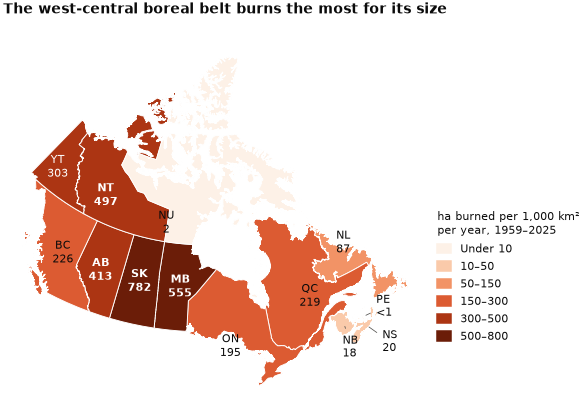

In [8]:
rate = (fires.groupby("province")["size_ha"].sum() / provinces.set_index("province")["land_km2"]
        * 1000 / fires["year"].nunique()).rename("rate")
choro = provinces.join(rate, on="province")
classes = [0, 10, 50, 150, 300, 500, 800]
norm = BoundaryNorm(classes, style.HEAT.N)

fig, ax = plt.subplots(figsize=(style.FULL_WIDTH, 4.3))
choro.plot(ax=ax, column="rate", cmap=style.HEAT, norm=norm, edgecolor="white", linewidth=0.6)
style.map_axes(ax)

offsets = {"NS": (220e3, -230e3), "NB": (-20e3, -330e3), "PE": (180e3, 140e3), "NL": (60e3, 120e3),
           "NU": (-250e3, -350e3), "NT": (0, -120e3), "QC": (0, -180e3), "ON": (0, -260e3), "BC": (0, -100e3)}
for _, row in choro.iterrows():
    point = row.geometry.representative_point()
    dx, dy = offsets.get(row["province"], (0, 0))
    dark = row["rate"] >= 300
    text = f"{row['province']}\n{row['rate']:,.0f}" if row["rate"] >= 1 else f"{row['province']}\n<1"
    if row["province"] in ("NS", "NB", "PE"):
        ax.annotate(text, xy=(point.x, point.y), xytext=(point.x + dx, point.y + dy), fontsize=7, ha="left",
                    va="center", color=style.INK, arrowprops=dict(arrowstyle="-", color=style.SECONDARY, lw=0.5))
    else:
        ax.text(point.x + dx, point.y + dy, text, fontsize=7.5, ha="center", va="center",
                color="white" if dark else style.INK, fontweight="bold" if row["rate"] >= 400 else "normal")

handles = [Patch(color=style.HEAT(norm((lo + hi) / 2)), label=f"{lo:,}–{hi:,}") for lo, hi in zip(classes, classes[1:])]
handles[0].set_label("Under 10")
ax.legend(handles=handles, title="ha burned per 1,000 km²\nper year, 1959–2025", loc="center left",
          bbox_to_anchor=(1.0, 0.35), fontsize=7.5, title_fontsize=7.5, alignment="left")
ax.set_title("The west-central boreal belt burns the most for its size")
style.save(fig, "fig7_choropleth_rate")

## Figure 8 – Where the area burned, decade by decade (Q4)

Burn perimeters of every fire ≥ 200 ha. The perimeter record starts in 1972, so the 1970s panel covers 1972–1979, and
the 2020s panel covers 2020–2024. Totals are from the perimeters.

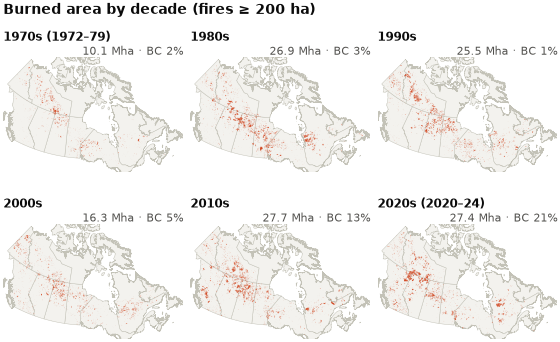

In [9]:
panel_decades = ["1970s", "1980s", "1990s", "2000s", "2010s", "2020s"]
spans = {"1970s": "1972–79", "2020s": "2020–24"}
bc_share = (perimeters.groupby(["decade", "agency"])["size_ha"].sum().unstack(fill_value=0)
            .pipe(lambda t: t["BC"] / t.sum(axis=1) * 100))

fig, axes = plt.subplots(2, 3, figsize=(style.FULL_WIDTH, 3.9), gridspec_kw={"wspace": 0.04, "hspace": 0.02})
xmin, ymin, xmax, ymax = provinces.total_bounds
for ax, decade in zip(axes.flat, panel_decades):
    burned = perimeters[perimeters["decade"] == decade]
    provinces.plot(ax=ax, color=style.LAND, edgecolor=style.BORDER, linewidth=0.3)
    burned.plot(ax=ax, color=style.ACCENT, linewidth=0, rasterized=True)
    style.map_axes(ax)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin + 0.08 * (ymax - ymin), ymax - 0.18 * (ymax - ymin))
    label = decade + (f" ({spans[decade]})" if decade in spans else "")
    ax.set_title(label, fontsize=8, pad=1)
    ax.text(1.0, 1.0, f"{burned['size_ha'].sum() / 1e6:.1f} Mha · BC {bc_share[decade]:.0f}%",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=7.5, color=style.SECONDARY)
fig.suptitle("Burned area by decade (fires ≥ 200 ha)", x=0.125, y=0.95, ha="left", fontsize=9, fontweight="bold")
style.save(fig, "fig8_perimeters_by_decade")